In [ ]:
from scripts.general_nn import generalNN
from scripts import plots
import importlib


from dataclasses import replace

from scripts.general_nn import generalNN
from scripts.settings import Settings
from scripts import plots


# Use a small training budget for this first experiment.
settings = Settings(
    warmup_updates=100,
    continuation_updates=100,
    number_of_replicates=1,

    # Check validation performance every 25 training updates.
    validation_interval=25,

    # Set the sizes of the calibration, validation, and test datasets.
    normalization_size=2048,
    validation_size=2048,
    test_size=8192,

    # Used only if we choose to train from a fixed dataset.
    static_training_size=8192,
)


In [ ]:

# dynamic_data:
# True: generate fresh training batches during each iteration.
# False: sample batches from one fixed training dataset.


# Create a new paper-style model that trades using stock and the variance information.
paper = generalNN(
    method="paper",
    settings=settings,
    dynamic_data=False,
    name="Paper network: stock + variance",
)

# Copy the settings and disable trading using variance.
control_settings = replace(settings, trade_variance=False)

# Create a new paper-style model restricted to stock trading.
control = generalNN(
    method="paper",
    settings=control_settings,
    dynamic_data=False,
)

# Create a new model using our smaller network design.
ours = generalNN(
    method="ours",
    settings=settings,
    dynamic_data=True,
    name="Our network: stock only",
)


# Keep our settings, but use the same instruments as the full reference.
settings_with_variance = replace(
    ours.settings,
    instruments=paper.settings.instruments,
    trade_variance=True,
)

ours_variance = generalNN(
    method="ours",
    settings=settings_with_variance,
    dynamic_data=ours.dynamic_data,
    name="Our network: stock + variance",
)

In [3]:
# Train and evaluate each newly created model.
for model in (paper, control, ours, ours_variance):

    print(f"\nTraining: {model.name}")

    # Prepare the training data and fit the hedging policies.
    model.train(verbose=True)

    # Measure the trained policies on separate test paths.
    model.evaluate()


Training: Paper network: stock + variance
paper_full_0_warmup: update 0, validation risk 6.35469
paper_full_0_warmup: update 100, validation risk 2.61810
paper_full_0_CVaR: update 0, validation risk 2.62167
paper_full_0_CVaR: update 100, validation risk 2.44961
paper_full_0_Entropic: update 0, validation risk 5.26523
paper_full_0_Entropic: update 100, validation risk 3.12171

Training: Paper style: stock only
paper_stock_0_warmup: update 0, validation risk 5.27709
paper_stock_0_warmup: update 100, validation risk 2.91749
paper_stock_0_CVaR: update 0, validation risk 2.90666
paper_stock_0_CVaR: update 100, validation risk 2.88922
paper_stock_0_Entropic: update 0, validation risk 8.41497
paper_stock_0_Entropic: update 100, validation risk 5.90067

Training: Our network: stock only
ours_0_warmup: update 0, validation risk 4.15072
ours_0_warmup: update 100, validation risk 2.80630
ours_0_CVaR: update 0, validation risk 2.80448
ours_0_CVaR: update 100, validation risk 2.80386
ours_0_Entrop

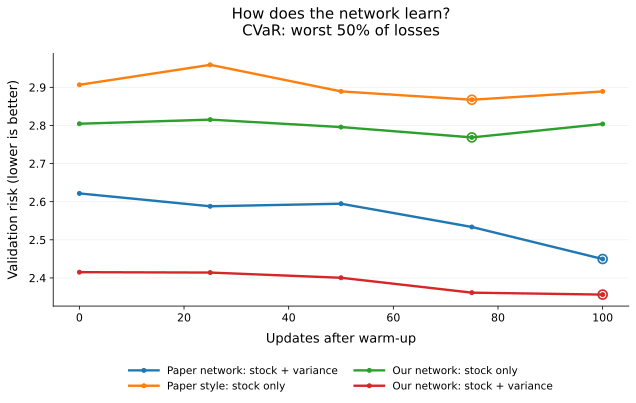

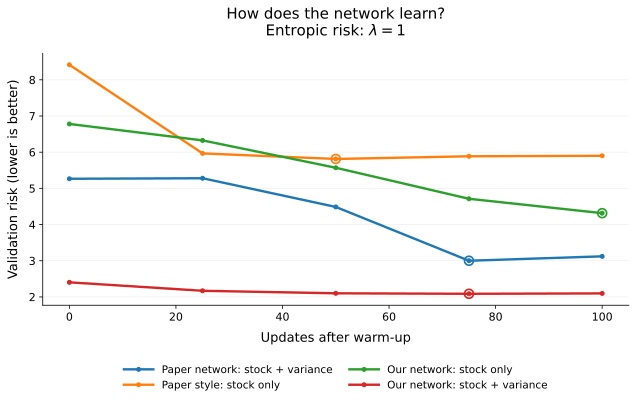

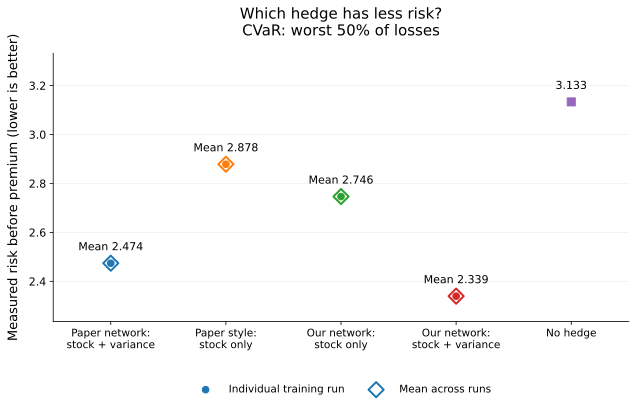

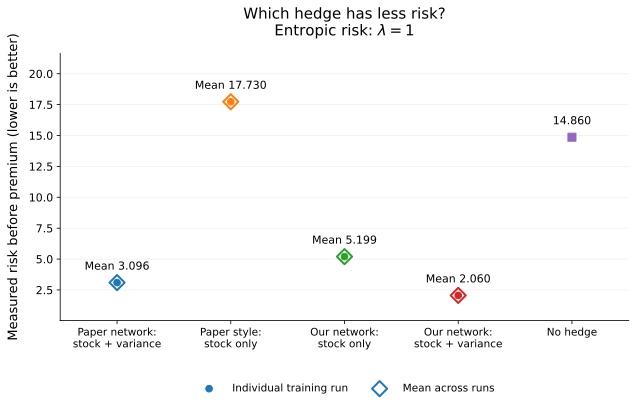

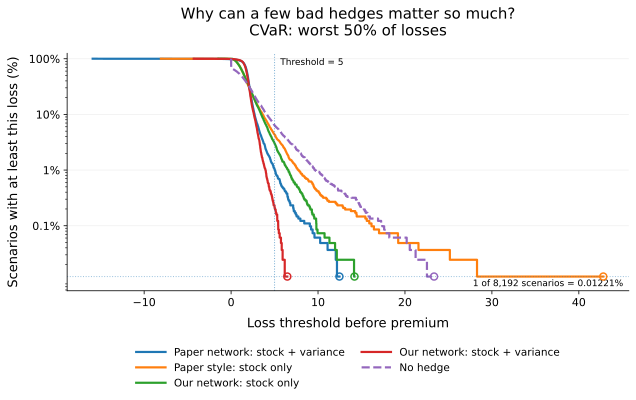

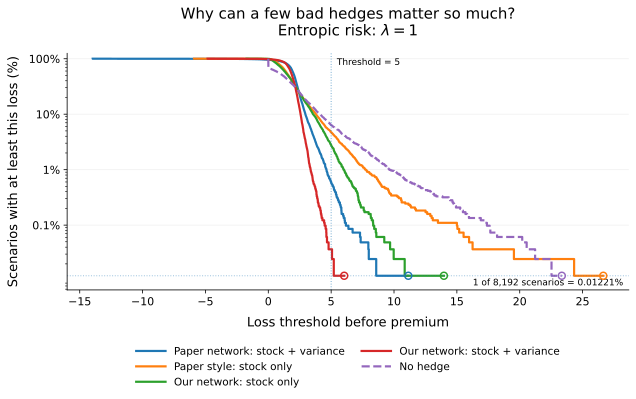

In [4]:
experiments = [paper, control, ours, ours_variance]

plots.plot_learning(experiments)
plots.plot_risk(experiments)
plots.plot_loss_tails(experiments)